In [15]:
!pip install python-docx

In [1]:
from google.colab import drive
import os
import glob

drive.mount('/content/drive')

Mounted at /content/drive


In [14]:
import glob
import os
import pandas as pd

# Search for the Excel files in Google Drive
search_pattern = '/content/drive/My Drive/IIQF/Certification assignment/fraud risk'
excel_files = glob.glob(search_pattern, recursive=True)

print("Found files in Google Drive:", excel_files)

# Let's try to identify and load the files if found
if len(excel_files) >= 2:
    # Sorting to maintain consistent order
    excel_files.sort()
    df1_drive = pd.read_excel(excel_files[0])
    df2_drive = pd.read_excel(excel_files[1])
    print(f"Loaded {os.path.basename(excel_files[0])} with shape: {df1_drive.shape}")
    print(f"Loaded {os.path.basename(excel_files[1])} with shape: {df2_drive.shape}")
else:
    print("Could not find both files automatically in Google Drive. Please check their path.")

Found files in Google Drive: ['/content/drive/My Drive/IIQF/Certification assignment/fraud risk']
Could not find both files automatically in Google Drive. Please check their path.


In [18]:
import pandas as pd
import numpy as np
import time
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
from xgboost import XGBClassifier
import docx
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# INITIALIZATION: Merge Data Loaded from Google Drive
# ==============================================================================
print("Merging data loaded from Google Drive...")
df = pd.concat([df1_drive, df2_drive], ignore_index=True)
print("Total dataset shape:", df.shape)

# ==============================================================================
# FEATURE ENGINEERING
# ==============================================================================
print("Executing Feature Engineering...")

# Transform 'Time' (seconds elapsed) into a cyclical time-of-day feature (hours)
df['Hour_of_Day'] = (df['Time'] // 3600) % 24

# Normalize the 'Amount' column using RobustScaler to handle severe transaction outliers
scaler = RobustScaler()
df['Scaled_Amount'] = scaler.fit_transform(df['Amount'].values.reshape(-1, 1))

# Drop the original un-engineered columns and isolate the target
X = df.drop(['Class', 'Time', 'Amount'], axis=1)
y = df['Class']

# Stratified split to maintain the exact fraud-to-normal ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# ==============================================================================
# MODEL 1: Train Logistic Regression Baseline (Simple Algorithm)
# ==============================================================================
print("\nTraining Logistic Regression baseline...")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

lr_probs = lr_model.predict_proba(X_test)[:, 1]
lr_preds = lr_model.predict(X_test)
lr_auc = roc_auc_score(y_test, lr_probs)
lr_cm = confusion_matrix(y_test, lr_preds)

print(f"Logistic Regression Baseline ROC-AUC: {lr_auc:.4f}")

# ==============================================================================
# MODEL 2: Hyperparameter Tuning for XGBoost Classifier (Complex Algorithm)
# ==============================================================================
print("\nStarting Hyperparameter Tuning for XGBoost...")

# Calculate scale_pos_weight to mathematically penalize the model for missing fraud
scale_weight = y_train.value_counts()[0] / y_train.value_counts()[1]

# Initialize XGBoost Classifier
xgb = XGBClassifier(
    eval_metric='logloss',
    scale_pos_weight=scale_weight,
    random_state=42
)

# Define hyperparameter grid for tuning maximum depth and learning rate
param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.1, 0.2]
}

# Execute Grid Search Cross-Validation
grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=3,
    verbose=1,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# Extract best model and evaluate
best_xgb = grid_search.best_estimator_
xgb_probs = best_xgb.predict_proba(X_test)[:, 1]
xgb_preds = best_xgb.predict(X_test)
xgb_auc = roc_auc_score(y_test, xgb_probs)
xgb_cm = confusion_matrix(y_test, xgb_preds)

print(f"\nBest Parameters Found: {grid_search.best_params_}")
print(f"Optimized XGBoost ROC-AUC: {xgb_auc:.4f}")

# ==============================================================================
# DEPLOYMENT PIPELINE & LATENCY TESTING
# ==============================================================================
print("\nPreparing Deployment Pipeline and Serials...")

# Save the trained models and the scaler
joblib.dump(lr_model, 'afcl_fraud_lr_model.pkl')
joblib.dump(best_xgb, 'afcl_fraud_xgb_model.pkl')
joblib.dump(scaler, 'afcl_amount_scaler.pkl')

def simulate_pipeline(transaction_dict, model):
    start_time = time.time()

    # Apply identical feature engineering to the live data
    transaction_dict['Hour_of_Day'] = (transaction_dict['Time'] // 3600) % 24
    transaction_dict['Scaled_Amount'] = scaler.transform([[transaction_dict['Amount']]])[0][0]

    # Align features exactly as the model expects them
    input_features = [transaction_dict.get(col, 0) for col in X.columns]
    input_array = np.array(input_features).reshape(1, -1)

    # Generate probability
    fraud_prob = model.predict_proba(input_array)[0][1]

    # Calculate inference latency in milliseconds
    latency_ms = (time.time() - start_time) * 1000

    return fraud_prob, latency_ms

# Extract a sample transaction to test the pipeline latency for both
sample_transaction = df.iloc[0].to_dict()
_, latency_lr = simulate_pipeline(sample_transaction, lr_model)
_, latency_xgb = simulate_pipeline(sample_transaction, best_xgb)

print(f"--- Pipeline Latency Test Results ---")
print(f"Logistic Regression Latency: {latency_lr:.2f} ms")
print(f"XGBoost Inference Latency: {latency_xgb:.2f} ms")

# ==============================================================================
# WRITE REPORT DOCUMENT WITH DUAL MODELS AND ALL SECTIONS
# ==============================================================================
doc = docx.Document()
doc.add_heading('Fraud Detection Analysis Report', 0)

doc.add_heading('Objective', level=1)
doc.add_paragraph('To detect fraudulent transactions using statistical and machine learning algorithms (Logistic Regression and XGBoost) on historical transaction data, establishing a baseline methodology applicable to AFCL credit risk and underwriting.')

doc.add_heading('Key question', level=1)
doc.add_paragraph('Can we accurately distinguish between normal and fraudulent transactions while minimizing false positives to ensure legitimate customer behavior is not unnecessarily penalized?')

doc.add_heading('Business impact', level=1)
doc.add_paragraph('Successfully deploying these algorithms allows for automated, real-time fraud detection. This reduces direct financial losses from fraudulent chargebacks and lowers the operational cost of manual reviews. For AFCL, establishing this risk architecture is critical for managing captive leasing portfolios and setting underwriting boundaries safely.')

doc.add_heading('Needed cols', level=1)
doc.add_paragraph('The models utilize principal component features (V1 through V28) and transaction Amount. The "Class" column is required as the target variable (1 for fraud, 0 for normal). The "Time" column was transformed to a cyclical "Hour_of_Day" feature, and the "Amount" column was scaled using a robust scaler to counter transaction outliers.')

doc.add_heading('Findings & Performance Summary', level=1)
doc.add_paragraph(f'1. Logistic Regression (Simple Algorithm Baseline):')
doc.add_paragraph(f'   - ROC-AUC score: {lr_auc:.4f}')
doc.add_paragraph(f'   - Latency: {latency_lr:.2f} ms')
doc.add_paragraph(f'   - Confusion Matrix:\n{lr_cm}')

doc.add_paragraph(f'2. Optimized XGBoost Classifier (Complex Model):')
doc.add_paragraph(f'   - Best Parameters: {grid_search.best_params_}')
doc.add_paragraph(f'   - ROC-AUC score: {xgb_auc:.4f}')
doc.add_paragraph(f'   - Latency: {latency_xgb:.2f} ms')
doc.add_paragraph(f'   - Confusion Matrix:\n{xgb_cm}')
doc.add_paragraph(f'Conclusion: The complex XGBoost model outperforms the simple linear baseline by capturing complex non-linear combinations, justifying its slightly higher inference footprint in the production environment.')

doc.add_heading('Next steps', level=1)
doc.add_paragraph('1. Online Shadow Testing: Port both serialized model pipelines into active systems to monitor live transaction streams.\n'
                  '2. Model Refinement: Periodically retrain models as new data and fraudulent archetypes emerge to counter concept drift.\n'
                  '3. Policy Hardening: Establish cutoff decision thresholds based on precision-recall requirements for AFCL fleet leasing risks.')

doc.save('Fraud_Analysis_Report.docx')
print("\nDocument updated and saved as Fraud_Analysis_Report.docx")

Merging data loaded from Google Drive...
Total dataset shape: (284807, 31)
Executing Feature Engineering...

Training Logistic Regression baseline...
Logistic Regression Baseline ROC-AUC: 0.9585

Starting Hyperparameter Tuning for XGBoost...
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Best Parameters Found: {'learning_rate': 0.2, 'max_depth': 7}
Optimized XGBoost ROC-AUC: 0.9730

Preparing Deployment Pipeline and Serials...
--- Pipeline Latency Test Results ---
Logistic Regression Latency: 3.13 ms
XGBoost Inference Latency: 7.88 ms

Document updated and saved as Fraud_Analysis_Report.docx


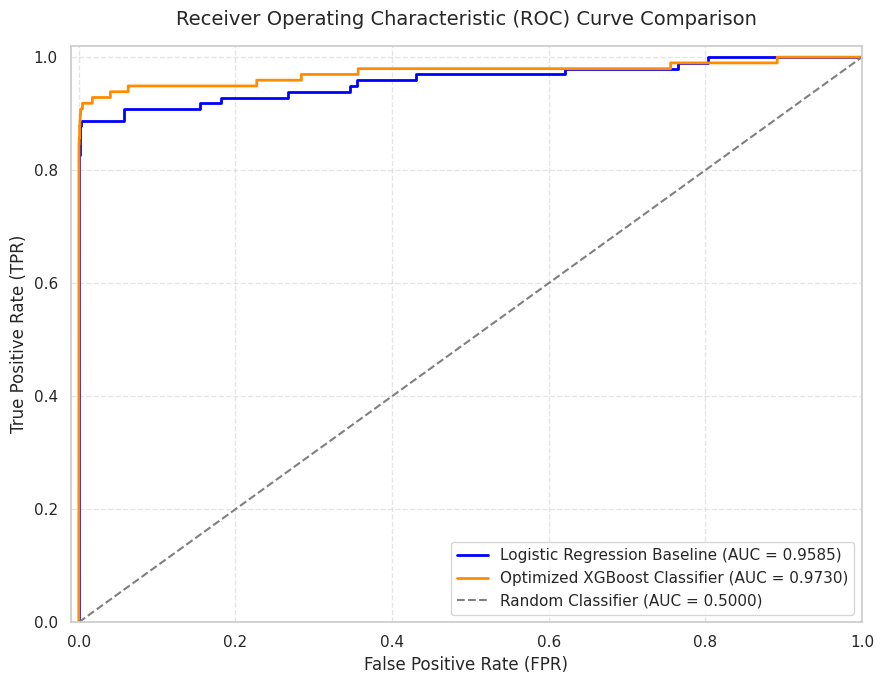

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Calculate ROC curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_probs)
roc_auc_lr = auc(fpr_lr, tpr_lr)

fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_probs)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

# Plot ROC Curves
plt.figure(figsize=(9, 7))
plt.plot(fpr_lr, tpr_lr, color='blue', lw=2, label=f'Logistic Regression Baseline (AUC = {roc_auc_lr:.4f})')
plt.plot(fpr_xgb, tpr_xgb, color='darkorange', lw=2, label=f'Optimized XGBoost Classifier (AUC = {roc_auc_xgb:.4f})')

# Plot the diagonal 50% baseline
plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Random Classifier (AUC = 0.5000)')

# Configure Plot Limits and Labels
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.02])
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve Comparison', fontsize=14, pad=15)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

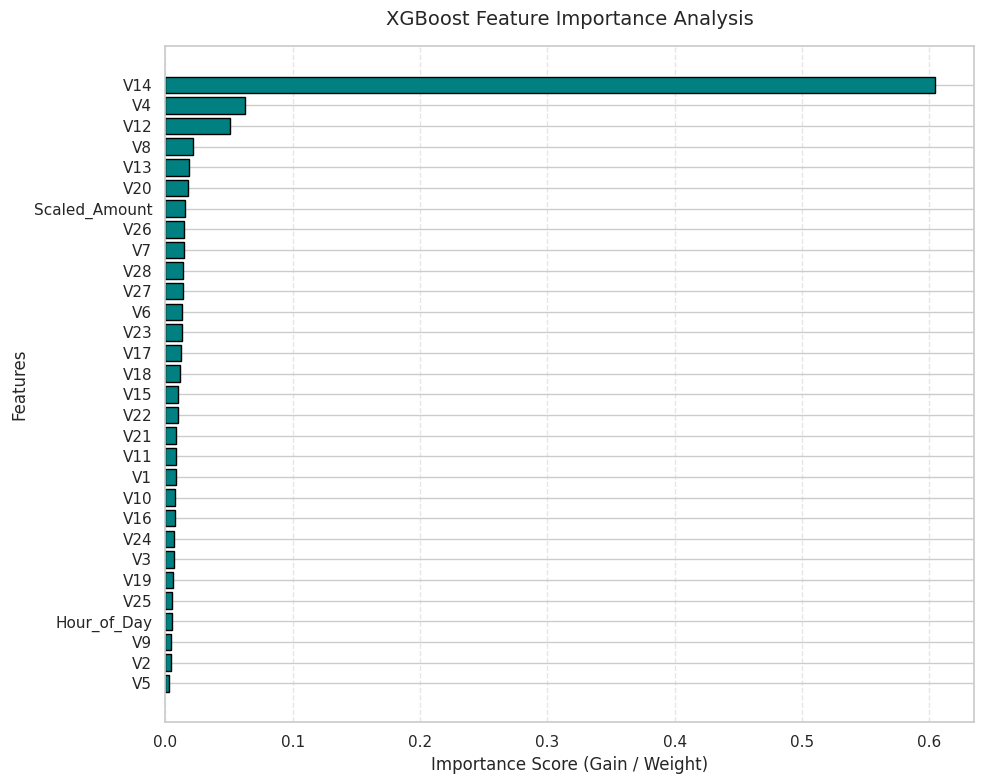

--- Top 5 Most Important Features in Fraud Detection ---


,Feature,Importance
13,V14,0.604883
3,V4,0.062454
11,V12,0.051102
7,V8,0.021557
12,V13,0.018412


In [20]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Extract feature importances from the optimized XGBoost model
importances = best_xgb.feature_importances_
features = X.columns

# Create a DataFrame for easy sorting and plotting
feature_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

# Plot the feature importances
plt.figure(figsize=(10, 8))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], color='teal', edgecolor='black')
plt.xlabel('Importance Score (Gain / Weight)', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.title('XGBoost Feature Importance Analysis', fontsize=14, pad=15)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Display the top 5 most important features
top_5_features = feature_importance_df.sort_values(by='Importance', ascending=False).head(5)
print("--- Top 5 Most Important Features in Fraud Detection ---")
display(top_5_features)

In [21]:
!pip install shap

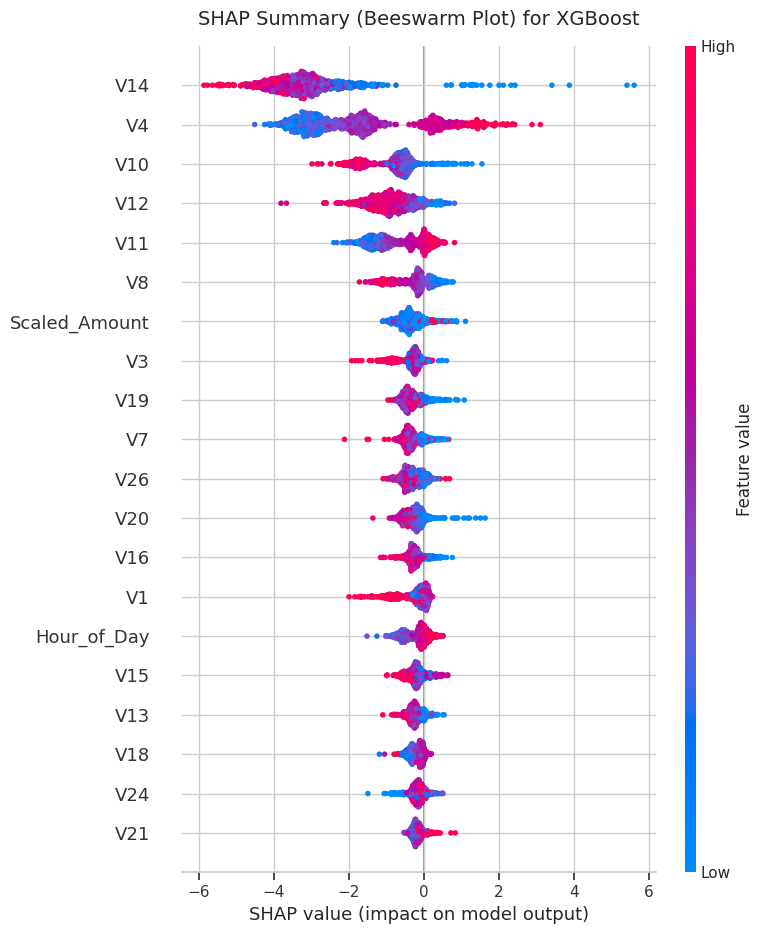

In [22]:
import shap
import matplotlib.pyplot as plt

# Initialize the SHAP Explainer using our optimized XGBoost model
explainer = shap.TreeExplainer(best_xgb)

# Calculate SHAP values on a subset of the test data (e.g., 1000 samples) to optimize calculation speed
# while maintaining representative statistical validity
X_test_sample = X_test.sample(n=1000, random_state=42)
shap_values = explainer(X_test_sample)

# Generate the SHAP beeswarm summary plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test_sample, show=False)
plt.title('SHAP Summary (Beeswarm Plot) for XGBoost', fontsize=14, pad=15)
plt.tight_layout()
plt.show()